# 12 — Statistical Validation Analysis: Pairwise McNemar Tests

This notebook provides a focused statistical-validation layer for the baseline predictive model comparison across the three validation domains:

- Credit Risk
- Healthcare
- Criminal Justice

For each domain, the five candidate models — **LR, DT, RF, XGB, and MLP** — are compared using pairwise **McNemar tests** on the same held-out test observations.

The analysis answers one question:

> **Do the candidate models exhibit statistically different classification behaviour within each validation domain?**

Because 10 pairwise comparisons are performed within each domain, **Holm correction** is applied to the resulting p-values to control the family-wise Type I error rate.

- **H₀:** There is no statistically significant difference in classification performance between the two candidate models.
- **H₁:** There is a statistically significant difference in classification performance between the two candidate models.
- **Significance level:** α = 0.05.

The primary dissertation outputs are three 5 × 5 heat maps of **Holm-adjusted p-values**, one for each validation domain. Raw p-values are retained only in the saved CSV output for reproducibility.

McNemar testing complements the baseline predictive comparison; it does **not** statistically test BPS or EES values.


In [1]:

# ============================================================
# 1. IMPORTS AND CONFIGURATION
# ============================================================

from pathlib import Path
from itertools import combinations
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests

from IPython.display import display, Markdown

# ------------------------------------------------------------
# Google Drive
# ------------------------------------------------------------
from google.colab import drive

try:
    drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or already mounted:", e)

ROOT_PATH = Path("/content/drive/MyDrive/Master_Research")
RESULTS_ROOT = ROOT_PATH / "07_Results"

OUTPUT_ROOT = RESULTS_ROOT / "12_stats_validation_analysis"
TABLES_PATH = OUTPUT_ROOT / "tables"
FIGURES_PATH = OUTPUT_ROOT / "figures"

TABLES_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Statistical settings
# ------------------------------------------------------------
ALPHA = 0.05
EXACT_DISCORDANT_THRESHOLD = 25
DPI = 600

MODEL_ORDER = ["LR", "DT", "RF", "XGB", "MLP"]

MODEL_ABBREVIATIONS = {
    "Logistic Regression": "LR",
    "Decision Tree": "DT",
    "Random Forest": "RF",
    "XGBoost": "XGB",
    "Extreme Gradient Boosting": "XGB",
    "MLP": "MLP",
    "Multi-Layer Perceptron": "MLP",
    "Multilayer Perceptron": "MLP",
}

# ------------------------------------------------------------
# Paths exactly matching Notebook 03
# ------------------------------------------------------------
DOMAIN_CONFIG = {
    "Credit Risk": {
        "results_folder": "german_credit",
        "baseline_folder": "03_baseline_modeling_german_credit",
    },
    "Healthcare": {
        "results_folder": "pima_diabetes",
        "baseline_folder": "03_baseline_modeling_pima_diabetes",
    },
    "Criminal Justice": {
        "results_folder": "compas",
        "baseline_folder": "03_baseline_modeling_compas",
    },
}

for domain, cfg in DOMAIN_CONFIG.items():
    base = RESULTS_ROOT / cfg["results_folder"] / cfg["baseline_folder"]
    cfg["prediction_file"] = base / "datasets" / "baseline_prediction_summary.csv"
    cfg["performance_file"] = base / "datasets" / "baseline_model_performance.csv"

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": DPI,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

print("Statistical-validation output:", OUTPUT_ROOT)

for domain, cfg in DOMAIN_CONFIG.items():
    print("\n", domain)
    print("Predictions:", cfg["prediction_file"])
    print("Performance:", cfg["performance_file"])


Mounted at /content/drive
Statistical-validation output: /content/drive/MyDrive/Master_Research/07_Results/12_stats_validation_analysis

 Credit Risk
Predictions: /content/drive/MyDrive/Master_Research/07_Results/german_credit/03_baseline_modeling_german_credit/datasets/baseline_prediction_summary.csv
Performance: /content/drive/MyDrive/Master_Research/07_Results/german_credit/03_baseline_modeling_german_credit/datasets/baseline_model_performance.csv

 Healthcare
Predictions: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/03_baseline_modeling_pima_diabetes/datasets/baseline_prediction_summary.csv
Performance: /content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/03_baseline_modeling_pima_diabetes/datasets/baseline_model_performance.csv

 Criminal Justice
Predictions: /content/drive/MyDrive/Master_Research/07_Results/compas/03_baseline_modeling_compas/datasets/baseline_prediction_summary.csv
Performance: /content/drive/MyDrive/Master_Research/07_Results/compas


## 2. Why the existing Notebook 03 output is sufficient

Notebook 03 already saves `baseline_prediction_summary.csv` with the following columns:

- `model_id`
- `model_name`
- `test_instance_position`
- `true_class`
- `predicted_class`
- `predicted_probability`

That file contains exactly what McNemar requires: the true class and each model's prediction for the **same held-out test observations**. This notebook therefore pivots the existing long-format file into one row per test observation and one prediction column per model.


In [2]:

# ============================================================
# 2. LOAD EXISTING NOTEBOOK 03 OUTPUTS
# ============================================================

def find_existing_file(primary_path, filename):
    '''
    Prefer the datasets folder used in Notebook 03, but fall back to
    the tables folder because Notebook 03 saves the same CSV there too.
    '''
    primary_path = Path(primary_path)

    if primary_path.exists():
        return primary_path

    # datasets -> tables fallback
    parts = list(primary_path.parts)
    if "datasets" in parts:
        idx = parts.index("datasets")
        parts[idx] = "tables"
        fallback = Path(*parts)

        if fallback.exists():
            return fallback

    raise FileNotFoundError(
        f"Could not find {filename}. Checked:\n"
        f"1. {primary_path}\n"
        f"2. matching tables folder fallback.\n\n"
        "Run Notebook 03 for that validation domain first, or update DOMAIN_CONFIG."
    )


def load_prediction_summary(domain, cfg):
    path = find_existing_file(
        cfg["prediction_file"],
        "baseline_prediction_summary.csv"
    )

    df = pd.read_csv(path)

    required = {
        "model_id",
        "model_name",
        "test_instance_position",
        "true_class",
        "predicted_class",
    }

    missing = required.difference(df.columns)

    if missing:
        raise KeyError(
            f"{domain}: baseline_prediction_summary.csv is missing {sorted(missing)}. "
            f"Available columns: {list(df.columns)}"
        )

    print(f"{domain}: loaded prediction summary from")
    print(path)
    print(f"Rows: {len(df):,}")

    return df


def load_performance_summary(domain, cfg):
    path = find_existing_file(
        cfg["performance_file"],
        "baseline_model_performance.csv"
    )

    df = pd.read_csv(path)

    required = {
        "model_name",
        "business_priority_score",
    }

    missing = required.difference(df.columns)

    if missing:
        raise KeyError(
            f"{domain}: baseline_model_performance.csv is missing {sorted(missing)}. "
            f"Available columns: {list(df.columns)}"
        )

    return df


In [3]:

# ============================================================
# 3. RECONSTRUCT ALIGNED TEST PREDICTIONS
# ============================================================

def prepare_paired_predictions(domain, prediction_summary):
    df = prediction_summary.copy()

    df["model_abbrev"] = (
        df["model_name"]
        .map(MODEL_ABBREVIATIONS)
        .fillna(df["model_name"])
    )

    # Keep only the five dissertation candidate models.
    df = df[df["model_abbrev"].isin(MODEL_ORDER)].copy()

    present_models = set(df["model_abbrev"].unique())
    missing_models = [m for m in MODEL_ORDER if m not in present_models]

    if missing_models:
        raise ValueError(
            f"{domain}: missing predictions for {missing_models}. "
            f"Models present: {sorted(present_models)}"
        )

    # Validate that each model has exactly one prediction per test position.
    duplicate_counts = (
        df.groupby(["test_instance_position", "model_abbrev"])
        .size()
    )

    if (duplicate_counts > 1).any():
        raise ValueError(
            f"{domain}: duplicate model predictions detected for the same test instance."
        )

    # Check that true_class is identical across models for every test position.
    true_class_check = (
        df.groupby("test_instance_position")["true_class"]
        .nunique()
    )

    if (true_class_check > 1).any():
        bad_positions = true_class_check[true_class_check > 1].index.tolist()[:10]
        raise ValueError(
            f"{domain}: true_class is inconsistent across models at positions "
            f"{bad_positions}."
        )

    y_true = (
        df.groupby("test_instance_position", as_index=True)["true_class"]
        .first()
        .sort_index()
    )

    pred_wide = (
        df.pivot(
            index="test_instance_position",
            columns="model_abbrev",
            values="predicted_class",
        )
        .sort_index()
    )

    # Enforce consistent model order.
    pred_wide = pred_wide[MODEL_ORDER]

    if pred_wide.isna().any().any():
        missing_by_model = pred_wide.isna().sum()
        raise ValueError(
            f"{domain}: incomplete paired predictions detected:\n{missing_by_model}"
        )

    if not y_true.index.equals(pred_wide.index):
        raise ValueError(
            f"{domain}: y_true and model-prediction indices are not aligned."
        )

    paired = pred_wide.copy()
    paired.insert(0, "y_true", y_true.astype(int).values)

    print(f"{domain}: {len(paired):,} fully aligned held-out observations.")
    display(paired.head())

    return paired


def identify_bps_champion(performance_df):
    champion_row = (
        performance_df
        .sort_values("business_priority_score", ascending=False)
        .iloc[0]
    )

    full_name = champion_row["model_name"]
    abbrev = MODEL_ABBREVIATIONS.get(full_name, full_name)

    return {
        "model_name": full_name,
        "model_abbrev": abbrev,
        "business_priority_score": float(
            champion_row["business_priority_score"]
        ),
    }


In [5]:
# ============================================================
# 4. LOAD ALL THREE VALIDATION DOMAINS
# ============================================================

domain_frames = {}

for domain, cfg in DOMAIN_CONFIG.items():
    prediction_summary = load_prediction_summary(domain, cfg)

    domain_frames[domain] = prepare_paired_predictions(
        domain,
        prediction_summary,
    )

print("\nAll three validation domains loaded successfully.")


Credit Risk: loaded prediction summary from
/content/drive/MyDrive/Master_Research/07_Results/german_credit/03_baseline_modeling_german_credit/datasets/baseline_prediction_summary.csv
Rows: 1,000
Credit Risk: 200 fully aligned held-out observations.


model_abbrev,y_true,LR,DT,RF,XGB,MLP
test_instance_position,,,,,,
0,0,0,0,0,0,0
1,0,0,0,0,0,1
2,1,0,1,1,1,1
3,0,0,1,1,0,0
4,1,0,0,0,0,0


Healthcare: loaded prediction summary from
/content/drive/MyDrive/Master_Research/07_Results/pima_diabetes/03_baseline_modeling_pima_diabetes/datasets/baseline_prediction_summary.csv
Rows: 770
Healthcare: 154 fully aligned held-out observations.


model_abbrev,y_true,LR,DT,RF,XGB,MLP
test_instance_position,,,,,,
0,0,1,1,1,1,1
1,0,0,0,0,0,0
2,0,0,0,0,0,0
3,1,0,1,0,0,0
4,0,0,0,0,0,0


Criminal Justice: loaded prediction summary from
/content/drive/MyDrive/Master_Research/07_Results/compas/03_baseline_modeling_compas/datasets/baseline_prediction_summary.csv
Rows: 17,500
Criminal Justice: 3,500 fully aligned held-out observations.


model_abbrev,y_true,LR,DT,RF,XGB,MLP
test_instance_position,,,,,,
0,0,0,1,0,0,0
1,0,0,1,0,0,0
2,0,0,0,1,0,0
3,1,1,0,1,1,1
4,0,0,0,0,0,0



All three validation domains loaded successfully.


## Statistical decision rule

For each model pair, McNemar's test compares paired correct/incorrect outcomes on the same held-out observations. Only **discordant cases** contribute to the test: observations where one model is correct and the other is incorrect.

Five candidate models produce 10 unique pairwise comparisons within each validation domain. Holm's sequential correction is therefore applied **separately within each domain** to control the family-wise probability of falsely declaring one or more model differences statistically significant.

The final decision is based on the Holm-adjusted p-value:

- **Adjusted p < 0.05:** reject H₀.
- **Adjusted p ≥ 0.05:** fail to reject H₀.


In [6]:

# ============================================================
# 5. MCNEMAR TEST FUNCTIONS
# ============================================================

def paired_correctness_table(y_true, pred_a, pred_b):
    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    pred_b = np.asarray(pred_b)

    correct_a = pred_a == y_true
    correct_b = pred_b == y_true

    both_correct = int(np.sum(correct_a & correct_b))
    a_correct_b_wrong = int(np.sum(correct_a & ~correct_b))
    a_wrong_b_correct = int(np.sum(~correct_a & correct_b))
    both_wrong = int(np.sum(~correct_a & ~correct_b))

    table = np.array([
        [both_correct, a_correct_b_wrong],
        [a_wrong_b_correct, both_wrong],
    ])

    return (
        table,
        both_correct,
        a_correct_b_wrong,
        a_wrong_b_correct,
        both_wrong,
    )


def run_mcnemar_pair(y_true, pred_a, pred_b, model_a, model_b):
    (
        table,
        both_correct,
        a_correct_b_wrong,
        a_wrong_b_correct,
        both_wrong,
    ) = paired_correctness_table(y_true, pred_a, pred_b)

    discordant_pairs = (
        a_correct_b_wrong
        + a_wrong_b_correct
    )

    if discordant_pairs == 0:
        statistic = 0.0
        raw_p = 1.0
        test_type = "No discordant pairs"

    else:
        use_exact = (
            discordant_pairs
            < EXACT_DISCORDANT_THRESHOLD
        )

        result = mcnemar(
            table,
            exact=use_exact,
            correction=not use_exact,
        )

        statistic = float(result.statistic)
        raw_p = float(result.pvalue)

        test_type = (
            "Exact McNemar"
            if use_exact
            else "Continuity-corrected McNemar"
        )

    return {
        "model_a": model_a,
        "model_b": model_b,
        "both_correct": both_correct,
        "a_correct_b_wrong": a_correct_b_wrong,
        "a_wrong_b_correct": a_wrong_b_correct,
        "both_wrong": both_wrong,
        "discordant_pairs": discordant_pairs,
        "mcnemar_statistic": statistic,
        "raw_p_value": raw_p,
        "test_type": test_type,
    }


def run_domain_pairwise_tests(domain, paired_df):
    rows = []

    for model_a, model_b in combinations(MODEL_ORDER, 2):

        result = run_mcnemar_pair(
            y_true=paired_df["y_true"].values,
            pred_a=paired_df[model_a].values,
            pred_b=paired_df[model_b].values,
            model_a=model_a,
            model_b=model_b,
        )

        result["validation_domain"] = domain
        rows.append(result)

    results = pd.DataFrame(rows)

    reject, adjusted_p, _, _ = multipletests(
        results["raw_p_value"].values,
        alpha=ALPHA,
        method="holm",
    )

    results["holm_adjusted_p_value"] = adjusted_p
    results["significant"] = reject

    results["decision"] = np.where(
        reject,
        "Reject H0",
        "Fail to reject H0",
    )

    results["interpretation"] = np.where(
        reject,
        "Statistically significant difference",
        "No statistically significant difference",
    )

    return results


In [7]:

# ============================================================
# 6. RUN ALL PAIRWISE TESTS
# ============================================================

all_results = []

for domain, paired_df in domain_frames.items():

    result = run_domain_pairwise_tests(
        domain,
        paired_df,
    )

    all_results.append(result)

    display(Markdown(f"### {domain} — Pairwise McNemar Results"))

    display(
        result[
            [
                "model_a",
                "model_b",
                "a_correct_b_wrong",
                "a_wrong_b_correct",
                "discordant_pairs",
                "raw_p_value",
                "holm_adjusted_p_value",
                "decision",
            ]
        ].round(4)
    )

all_results_df = pd.concat(
    all_results,
    ignore_index=True,
)

all_results_file = (
    TABLES_PATH
    / "mcnemar_pairwise_results_all_domains.csv"
)

all_results_df.to_csv(
    all_results_file,
    index=False,
)

print("Saved:", all_results_file)


### Credit Risk — Pairwise McNemar Results

,model_a,model_b,a_correct_b_wrong,a_wrong_b_correct,discordant_pairs,raw_p_value,holm_adjusted_p_value,decision
0,LR,DT,31,20,51,0.1614,1.0000,Fail to reject H0
1,LR,RF,13,15,28,0.8501,1.0000,Fail to reject H0
2,LR,XGB,13,19,32,0.3768,1.0000,Fail to reject H0
3,LR,MLP,26,21,47,0.5596,1.0000,Fail to reject H0
4,DT,RF,15,28,43,0.0673,0.6053,Fail to reject H0
5,DT,XGB,8,25,33,0.0053,0.0535,Fail to reject H0
6,DT,MLP,24,30,54,0.4962,1.0000,Fail to reject H0
7,RF,XGB,9,13,22,0.5235,1.0000,Fail to reject H0
8,RF,MLP,22,15,37,0.3239,1.0000,Fail to reject H0
9,XGB,MLP,28,17,45,0.1360,1.0000,Fail to reject H0


### Healthcare — Pairwise McNemar Results

,model_a,model_b,a_correct_b_wrong,a_wrong_b_correct,discordant_pairs,raw_p_value,holm_adjusted_p_value,decision
0,LR,DT,10,19,29,0.1374,1.0000,Fail to reject H0
1,LR,RF,4,10,14,0.1796,1.0000,Fail to reject H0
2,LR,XGB,5,16,21,0.0266,0.2660,Fail to reject H0
3,LR,MLP,6,8,14,0.7905,1.0000,Fail to reject H0
4,DT,RF,14,11,25,0.6892,1.0000,Fail to reject H0
5,DT,XGB,14,16,30,0.8551,1.0000,Fail to reject H0
6,DT,MLP,20,13,33,0.2963,1.0000,Fail to reject H0
7,RF,XGB,3,8,11,0.2266,1.0000,Fail to reject H0
8,RF,MLP,10,6,16,0.4545,1.0000,Fail to reject H0
9,XGB,MLP,15,6,21,0.0784,0.7052,Fail to reject H0


### Criminal Justice — Pairwise McNemar Results

,model_a,model_b,a_correct_b_wrong,a_wrong_b_correct,discordant_pairs,raw_p_value,holm_adjusted_p_value,decision
0,LR,DT,238,242,480,0.8911,1.0000,Fail to reject H0
1,LR,RF,266,795,1061,0.0000,0.0000,Reject H0
2,LR,XGB,163,224,387,0.0023,0.0137,Reject H0
3,LR,MLP,190,198,388,0.7223,1.0000,Fail to reject H0
4,DT,RF,277,802,1079,0.0000,0.0000,Reject H0
5,DT,XGB,183,240,423,0.0065,0.0259,Reject H0
6,DT,MLP,255,259,514,0.8947,1.0000,Fail to reject H0
7,RF,XGB,725,257,982,0.0000,0.0000,Reject H0
8,RF,MLP,771,250,1021,0.0000,0.0000,Reject H0
9,XGB,MLP,175,122,297,0.0025,0.0137,Reject H0


Saved: /content/drive/MyDrive/Master_Research/07_Results/12_stats_validation_analysis/tables/mcnemar_pairwise_results_all_domains.csv


In [8]:

# ============================================================
# 7. HEAT-MAP FUNCTIONS
# ============================================================

def build_pvalue_matrix(results):
    matrix = pd.DataFrame(
        np.nan,
        index=MODEL_ORDER,
        columns=MODEL_ORDER,
    )

    np.fill_diagonal(
        matrix.values,
        1.0,
    )

    for _, row in results.iterrows():
        a = row["model_a"]
        b = row["model_b"]
        p = float(row["holm_adjusted_p_value"])

        matrix.loc[a, b] = p
        matrix.loc[b, a] = p

    return matrix


def format_pvalue(value):
    if value < 0.001:
        return "<0.001"

    return f"{value:.3f}"


def plot_mcnemar_heatmap(domain, results, output_path):
    matrix = build_pvalue_matrix(results)

    fig, ax = plt.subplots(
        figsize=(7.6, 6.2)
    )

    image = ax.imshow(
        matrix.values,
        vmin=0,
        vmax=1,
        aspect="equal",
    )

    cbar = fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04,
    )

    cbar.set_label(
        "Holm-adjusted p-value"
    )

    ax.set_xticks(
        np.arange(len(MODEL_ORDER))
    )
    ax.set_yticks(
        np.arange(len(MODEL_ORDER))
    )

    ax.set_xticklabels(MODEL_ORDER)
    ax.set_yticklabels(MODEL_ORDER)

    ax.set_xlabel("Candidate Model")
    ax.set_ylabel("Candidate Model")

    ax.set_title(
        f"Statistical Validation of Predictive Model Comparisons — {domain}",
        pad=14,
    )

    for i in range(len(MODEL_ORDER)):
        for j in range(len(MODEL_ORDER)):

            if i == j:
                label = "—"

            else:
                p = matrix.iloc[i, j]
                marker = "*" if p < ALPHA else ""
                label = (
                    f"{format_pvalue(p)}{marker}"
                )

            # Choose annotation colour from the actual heat-map cell brightness.
            # This preserves the existing colour map while ensuring readable text.
            cell_value = matrix.iloc[i, j]
            rgba = image.cmap(image.norm(cell_value))
            luminance = (
                0.299 * rgba[0]
                + 0.587 * rgba[1]
                + 0.114 * rgba[2]
            )
            text_color = "black" if luminance > 0.55 else "white"

            ax.text(
                j,
                i,
                label,
                ha="center",
                va="center",
                fontsize=9,
                color=text_color,
            )

    ax.set_xticks(
        np.arange(-0.5, len(MODEL_ORDER), 1),
        minor=True,
    )
    ax.set_yticks(
        np.arange(-0.5, len(MODEL_ORDER), 1),
        minor=True,
    )

    ax.grid(
        which="minor",
        linewidth=0.8,
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False,
    )

    fig.text(
        0.5,
        0.015,
        (
            "Note: Cells report Holm-adjusted p-values from pairwise McNemar tests. "
            f"* indicates statistical significance at α = {ALPHA:.2f}. "
            "Diagonal comparisons are not applicable."
        ),
        ha="center",
        va="bottom",
        fontsize=8.5,
        wrap=True,
    )

    fig.tight_layout(
        rect=[0, 0.055, 1, 1]
    )

    output_path = Path(output_path)

    fig.savefig(
        output_path,
        dpi=DPI,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print("Saved:", output_path)

    return matrix


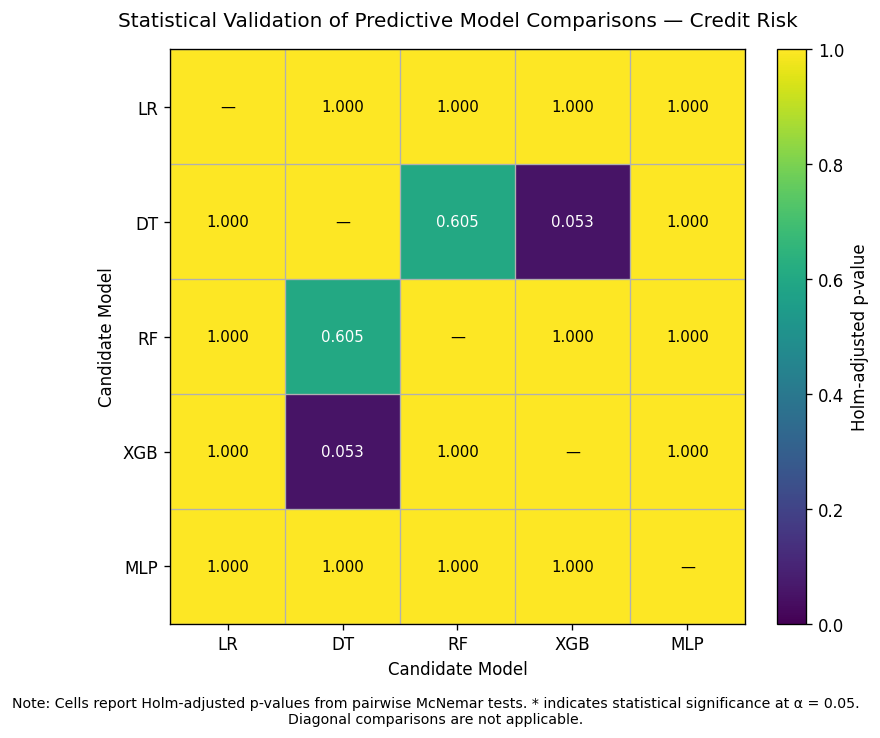

Saved: /content/drive/MyDrive/Master_Research/07_Results/12_stats_validation_analysis/figures/McNemar_Statistical_Validation_Credit_Risk.png


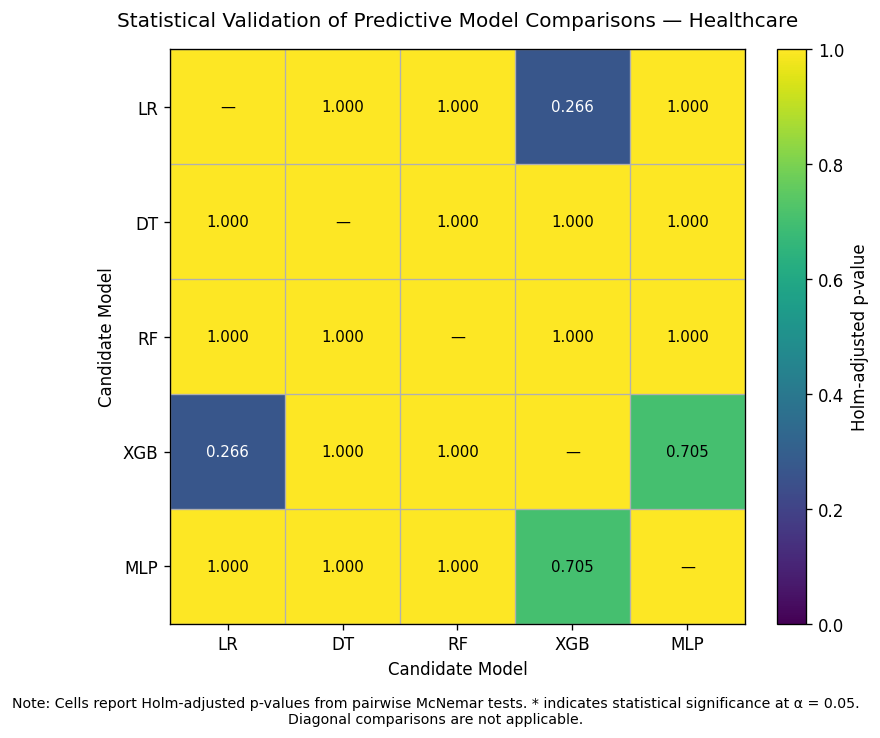

Saved: /content/drive/MyDrive/Master_Research/07_Results/12_stats_validation_analysis/figures/McNemar_Statistical_Validation_Healthcare.png


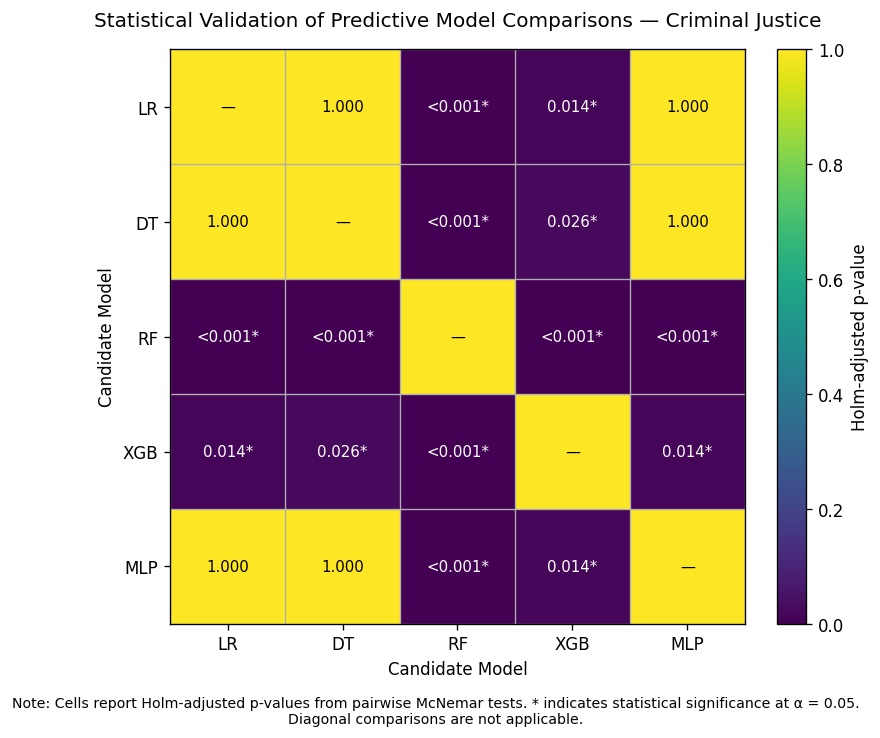

Saved: /content/drive/MyDrive/Master_Research/07_Results/12_stats_validation_analysis/figures/McNemar_Statistical_Validation_Criminal_Justice.png

Generated figures:
- Credit Risk: /content/drive/MyDrive/Master_Research/07_Results/12_stats_validation_analysis/figures/McNemar_Statistical_Validation_Credit_Risk.png
- Healthcare: /content/drive/MyDrive/Master_Research/07_Results/12_stats_validation_analysis/figures/McNemar_Statistical_Validation_Healthcare.png
- Criminal Justice: /content/drive/MyDrive/Master_Research/07_Results/12_stats_validation_analysis/figures/McNemar_Statistical_Validation_Criminal_Justice.png


In [9]:

# ============================================================
# 8. GENERATE THE THREE DISSERTATION HEAT MAPS
# ============================================================

heatmap_files = {}

for domain in DOMAIN_CONFIG:

    domain_results = all_results_df[
        all_results_df["validation_domain"] == domain
    ].copy()

    safe_domain = (
        domain
        .replace(" ", "_")
        .replace("-", "_")
    )

    figure_file = (
        FIGURES_PATH
        / f"McNemar_Statistical_Validation_{safe_domain}.png"
    )

    plot_mcnemar_heatmap(
        domain=domain,
        results=domain_results,
        output_path=figure_file,
    )

    heatmap_files[domain] = figure_file

print("\nGenerated figures:")

for domain, path in heatmap_files.items():
    print(f"- {domain}: {path}")


In [ ]:
# ============================================================
# FINAL OUTPUT CHECK
# ============================================================

print("=" * 72)
print("STATISTICAL VALIDATION COMPLETE")
print("=" * 72)

print("\nAnalysis:")
print("- Pairwise McNemar tests")
print("- Five candidate models: LR, DT, RF, XGB, MLP")
print("- Ten unique pairwise comparisons per validation domain")
print("- Holm correction applied separately within each domain")
print(f"- Significance threshold: alpha = {ALPHA}")

print("\nPrimary dissertation outputs:")
for domain, path in heatmap_files.items():
    print(f"- {domain}: {path.name}")

print("\nReproducibility output:")
print(f"- {all_results_file.name}")
print("  Contains both raw and Holm-adjusted p-values.")

print("\nDecision rule:")
print(f"- Holm-adjusted p < {ALPHA}: Reject H0")
print(f"- Holm-adjusted p >= {ALPHA}: Fail to reject H0")

print("=" * 72)


STATISTICAL VALIDATION COMPLETE

Analysis:
- Pairwise McNemar tests
- Five candidate models: LR, DT, RF, XGB, MLP
- Ten unique pairwise comparisons per validation domain
- Holm correction applied separately within each domain
- Significance threshold: alpha = 0.05

Primary dissertation outputs:
- Credit Risk: McNemar_Statistical_Validation_Credit_Risk.png
- Healthcare: McNemar_Statistical_Validation_Healthcare.png
- Criminal Justice: McNemar_Statistical_Validation_Criminal_Justice.png

Reproducibility output:
- mcnemar_pairwise_results_all_domains.csv
  Contains both raw and Holm-adjusted p-values.

Decision rule:
- Holm-adjusted p < 0.05: Reject H0
- Holm-adjusted p >= 0.05: Fail to reject H0
